---

MRI analysis 

---

In [ ]:
# autoload
%load_ext autoreload
%autoreload 2
from pgl import pgl, pglDatabase, pglActions, pglFlywheel, pglAFNI, pglActionsMRI, pglActionsMNE, pglActionsFixes


---

Load behavioral data

---

In [ ]:
pgl.importSettings()

In [ ]:
newSession = pglActions.loadSession.execute()
if newSession: 
    session = newSession
    session.print()

---

Fix missing volume triggers

---

In [ ]:
fixVolumeTimes = pglActionsFixes.fixVolumeTimes()
newSession = fixVolumeTimes.execute(session=session)
if newSession: 
    session = newSession
    session.print()

In [ ]:
session.display()

In [ ]:
session.print()

---

Load data from flywheel

---

In [ ]:
newSession = pglActions.loadFlywheel().execute(session=session, showScanCounts=False)
if newSession: 
    session = newSession
    session.print()

In [ ]:
session.mri.print(match='nsdmini')

In [ ]:
from pgl.pglPlots import pglScanTimelinePlot

# Zero-based (scanIndex, runIndex) pairs.
# Scan 0, the T1, remains unmatched.
proposedMatch = [(4, 0), (5, 1), (6, 2), (10, 3), (11, 4), (12, 5), (17,6), (21, 7), (22, 8), (23, 9)]
proposedMatch = (6, 2)
timeline = pglScanTimelinePlot(
    pglRuns=session.runs,
    pglScans=session.mri.scans,
    proposedMatch=proposedMatch,
    alignmentMode='first',
    volumeMarkerStyle='tick',
    showTrialSegments=True,
    showBehaviorVolumes=True,
    zoom=True,
)

#print(f"MRI shift: {timeline.getAlignmentOffset():+.3f} sec")
timeline.show()

In [ ]:
session.saveRawSession()

In [ ]:
session.setScanRunMatches((4, 0))
session.saveScanRunMatches("~/data/scanRunMatches-test.json")

expected = session.getScanRunMatches()
session.setScanRunMatches([])
restored = session.loadScanRunMatches("~/data/scanRunMatches-test.json")

assert restored == expected
session.printScanRunMatches()

In [ ]:
for scanIndex, runIndex in proposedMatch:
    scan = session.mri.scans[scanIndex]
    summary = scan.getScanSummary(readHeaders=True)

    print(f"\nScan {scanIndex}: {scan.name} → Run {runIndex}")
    print(f"  scanDims:  {summary.get('scanDims')!r}")
    print(f"  trSeconds: {summary.get('trSeconds')!r}")

In [ ]:
session.mri.print(match='nsdmini')

---

AFNI: check availability and optional install

---

In [ ]:
afni = pglAFNI(directory="~/proj/afni/abin")
available = afni.checkAvailable("3dvolreg")

In [ ]:
afni = pglAFNI()
afni.install()

In [ ]:
pglActions.help()


In [ ]:
from pgl import pglDatabase
session = pglDatabase.loadSession(125)
session.setScanRunMatches([(4, 0), (5, 1), (6, 2), (10, 3), (11, 4), (12, 5), (17,6), (21, 7), (22, 8), (23, 9)])

(pglDatabase:_reconstructSessionBundle) Restored 1 scan/run matches by acquisition identity; no matching action was replayed.
=================================== Session ====================================
  Source checkpoint : 125
  Description       : Persistence test: original MRI scan 4 and behavioral run 0 only. Indices in this subset are both zero; acquisition UUIDs are preserved. Inherited history describes the parent processing; subset selection was performed manually.
  Runs              : 1
  Filesystem        : pglcheckpoint
  MEG/EEG data      : None
  MRI data          : 1 scans

---------------------------- Experiment and subject ----------------------------
  nsd-mini / sdbp_nsdmini_0002

------------------------------------ Run 1 -------------------------------------
Experiment: nsd-mini | Subject ID: sdbp_nsdmini_0002
Session: session_2026-11-13 | Run: run_12-28-39
2026-11-13T12:32:11.679832-08:00
Duration: 6 mins 16s
Number of volume triggers: 240
Median time between

Timeline alignment: clock. Behavioral timestamps remain unchanged.
  Volume correspondence is ordinal: first ↔ first, second ↔ second, etc.
  Scan 0 ↔ Run 0: 240 pairs; MRI shift=+0.000000 s.
    After alignment: RMS=2792.495 ms; max absolute difference=10919.070 ms.


/Users/justin/proj/pgl/pgl/pglSession.py:2717: RuntimeWarning: Scan 0 / Run 0: 241 MRI volumes versus 240 behavioral triggers. Scatter and bestMatch use the first 240 ordinal pairs. Internal missing/extra triggers can invalidate subsequent pairings.
  plot = pglScanTimelinePlot(


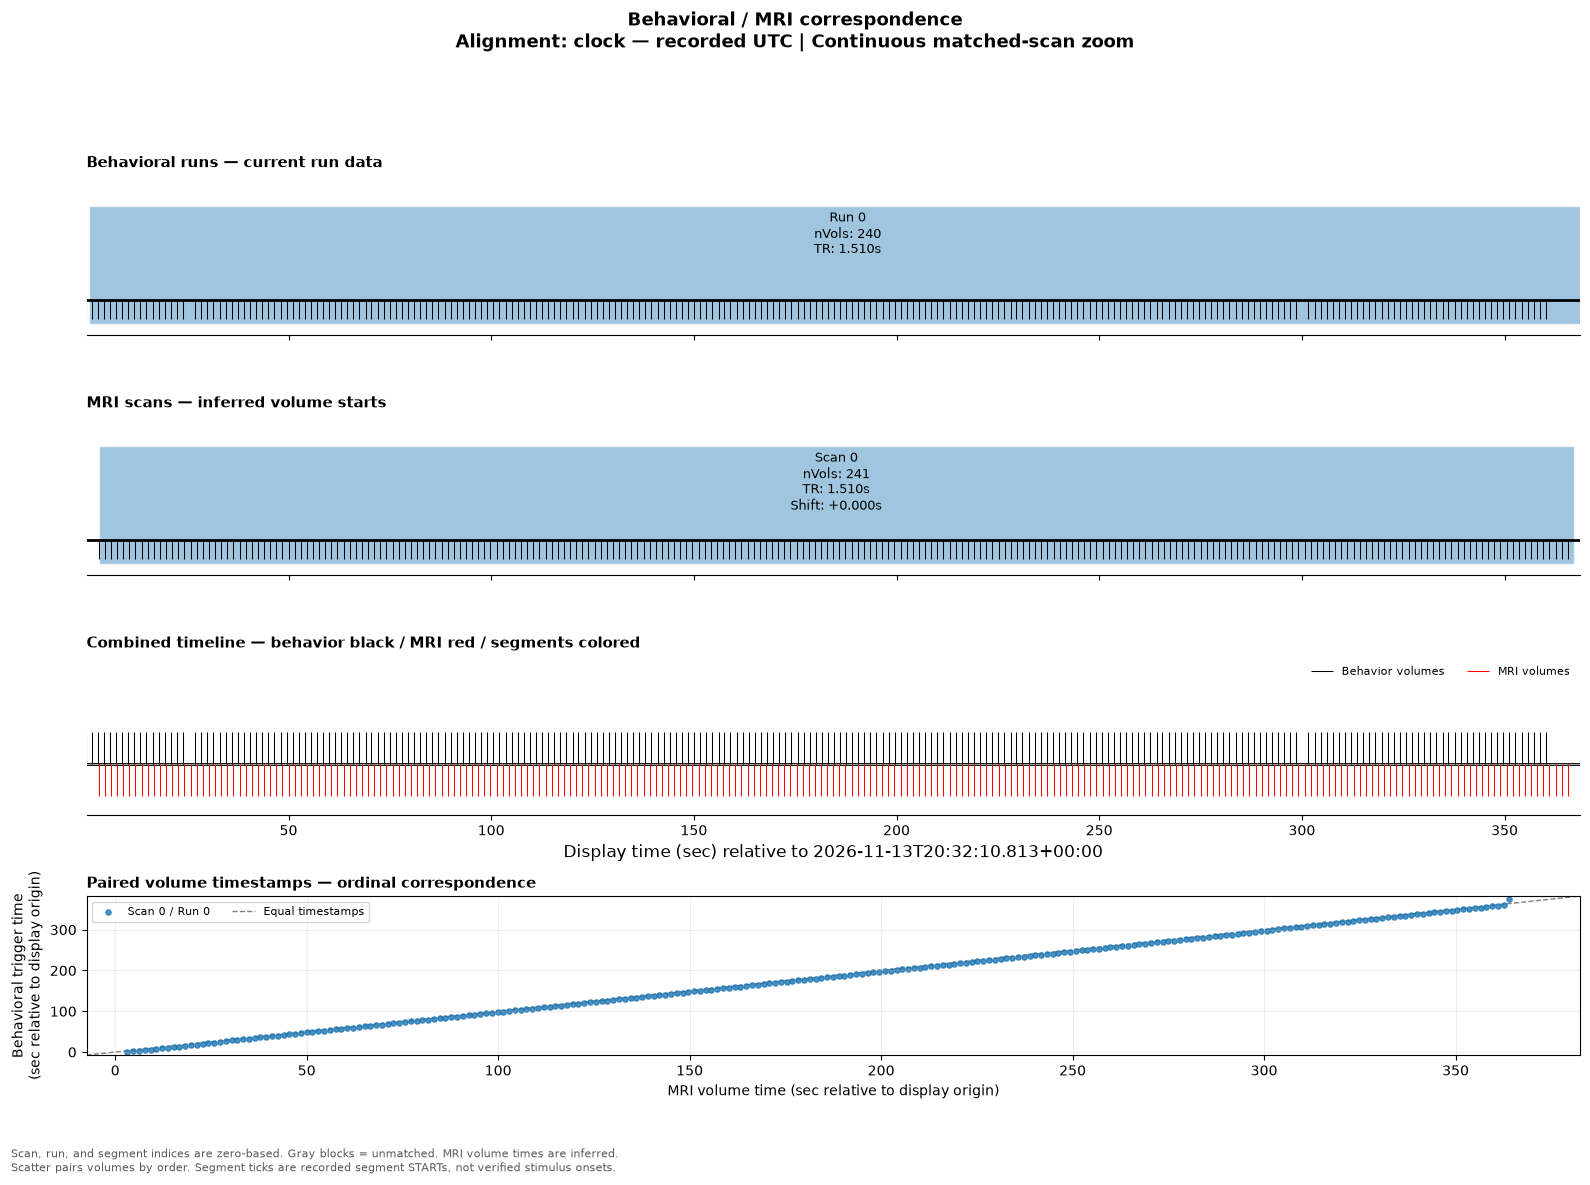

In [4]:
session.displayScanRunMapping()